## Algorithm: Solving the Viscous Burgers' Equation with FFT

### The PDE

$$\frac{\partial u}{\partial t} = -u \frac{\partial u}{\partial x} + \nu \frac{\partial^2 u}{\partial x^2}$$

Two competing effects:

- **Nonlinear advection** ($-u\, u_x$): each point travels at a speed proportional to its own value. Taller parts move faster, so the wave steepens and eventually "crashes" (forms a shock).
- **Viscous diffusion** ($\nu\, u_{xx}$): smooths out sharp features, just like the heat equation.

With $\nu = 0.001$ (very small), advection dominates and you get a near-shock -- a steep front that diffusion just barely prevents from breaking.

### Initial Condition

$u_0(x) = \text{sech}(x) = 1/\cosh(x)$ -- a smooth bell-shaped pulse centered at $x = 0$.

### How `rhsBurgers` works

At each time step, given the current $u(x)$:

1. **FFT** $u$ $\to$ $\hat{u}$
2. **First derivative**: $\widehat{u_x} = i\kappa\, \hat{u}$ $\to$ iFFT $\to$ $u_x$
3. **Second derivative**: $\widehat{u_{xx}} = -\kappa^2\, \hat{u}$ $\to$ iFFT $\to$ $u_{xx}$
4. **Combine**: $du/dt = -u \cdot u_x + \nu \cdot u_{xx}$

The advection term is **nonlinear** ($-u \cdot u_x$, not $-c \cdot u_x$). The wave speed is $u$ itself, not a constant. This makes it impossible to decouple modes in Fourier space, which is why integration must be done in the spatial domain.

### Why the wave "crashes"

Since taller points ($u \approx 1$) move faster than shorter points ($u \approx 0$):

- The **right side** of the pulse (where $u$ drops from 1 to 0) gets compressed -- the fast peak overtakes the slow base
- The **left side** (where $u$ rises from 0 to 1) gets stretched
- Result: a steepening right edge that forms a near-vertical front (shock)
- The tiny $\nu = 0.001$ adds just enough diffusion to keep the solution smooth, creating a thin "shock layer"

### Comparison with Heat and Wave equations

| | Heat | Wave | Burgers |
|---|---|---|---|
| PDE | $u_t = a^2 u_{xx}$ | $u_t = -c\, u_x$ | $u_t = -u\, u_x + \nu\, u_{xx}$ |
| Nonlinear? | No | No | **Yes** ($u \cdot u_x$) |
| Integration domain | Fourier | Either | **Spatial only** |
| Behavior | Smoothing | Translation | Shock formation + diffusion |

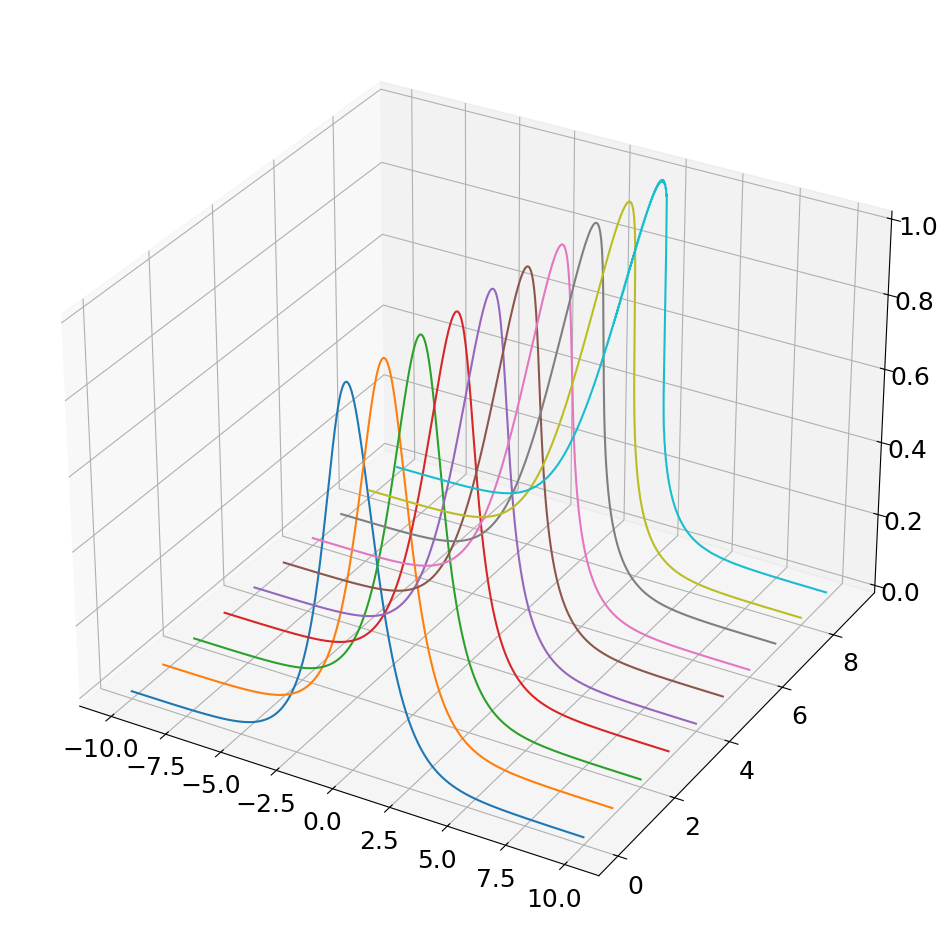

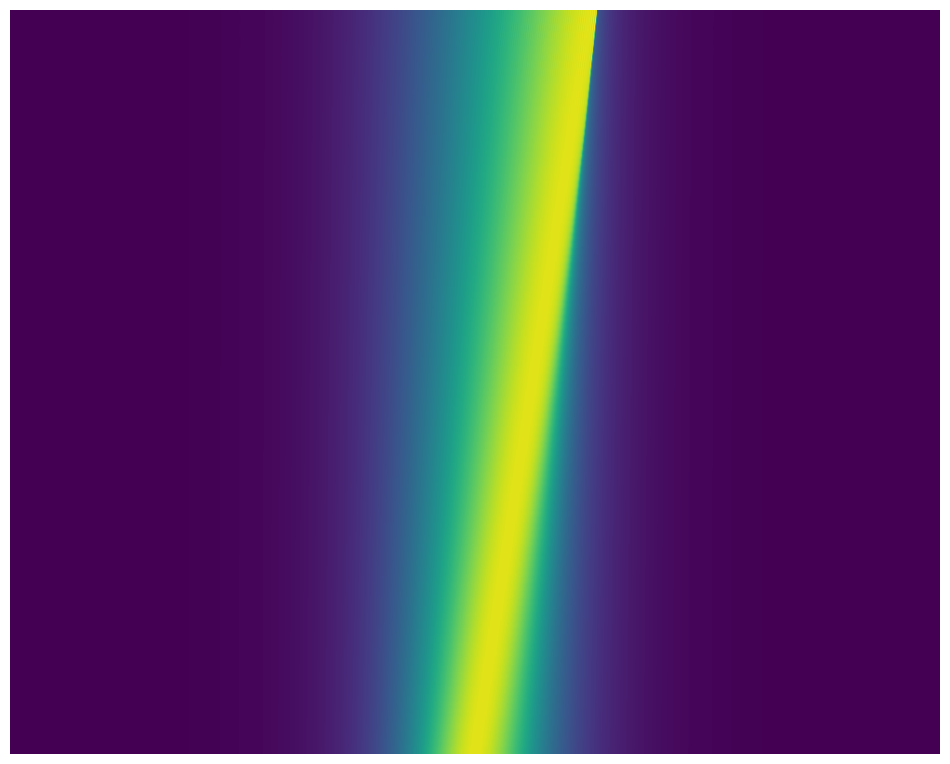

In [1]:


import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from mpl_toolkits.mplot3d import axes3d
plt.rcParams['figure.figsize'] = [12, 12]
plt.rcParams.update({'font.size': 18})

nu = 0.001 # Diffusion constant
L = 20     # Length of domain
N = 1000   # Number of discretization points
dx = L/N
x = np.arange(-L/2,L/2,dx) # Define x domain

# Define discrete wavenumbers
kappa = 2*np.pi*np.fft.fftfreq(N, d=dx)

# Initial condition
u0 = 1/np.cosh(x)

# Simulate PDE in spatial domain
dt = 0.025
t = np.arange(0,100*dt,dt)

def rhsBurgers(u,t,kappa,nu):
    uhat = np.fft.fft(u)
    d_uhat = (1j)*kappa*uhat
    dd_uhat = -np.power(kappa,2)*uhat
    d_u = np.fft.ifft(d_uhat)
    dd_u = np.fft.ifft(dd_uhat)
    du_dt = -u * d_u + nu*dd_u
    return du_dt.real

u = odeint(rhsBurgers,u0,t,args=(kappa,nu))

# Waterfall plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

u_plot = u[0:-1:10,:]
for j in range(u_plot.shape[0]):
    ys = j*np.ones(u_plot.shape[1])
    ax.plot(x,ys,u_plot[j,:])
    
# Image plot
plt.figure()
plt.imshow(np.flipud(u), aspect=8)
plt.axis('off')
plt.show()

 



## Inviscid Burgers' Equation ($\nu = 0$)

$$\frac{\partial u}{\partial t} = -u \frac{\partial u}{\partial x}$$

With no diffusion to smooth things out, the wave steepens into an actual discontinuity (shock). The spectral method will develop **Gibbs oscillations** near the shock -- ringing artifacts from trying to represent a discontinuity with a finite Fourier series. This is expected and illustrates why specialized shock-capturing methods (e.g., WENO, Godunov) are used in practice.

We use a shorter time window since the shock forms quickly and the solution becomes numerically unstable soon after.

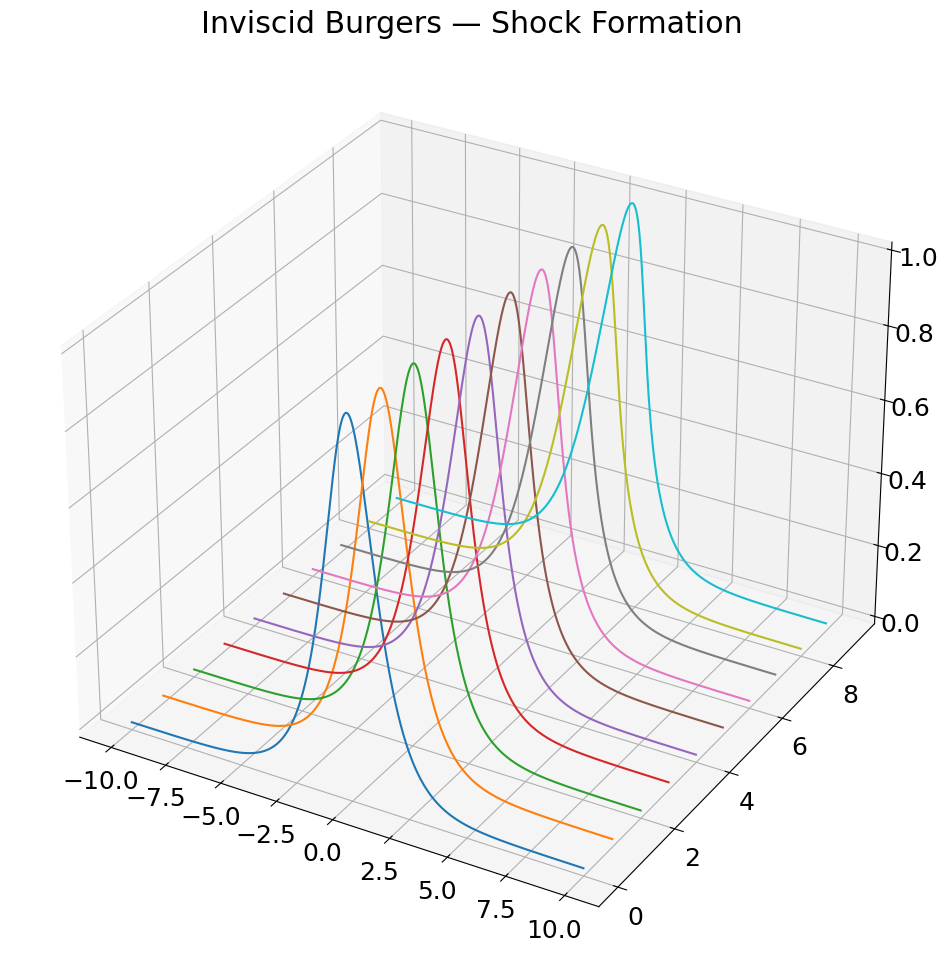

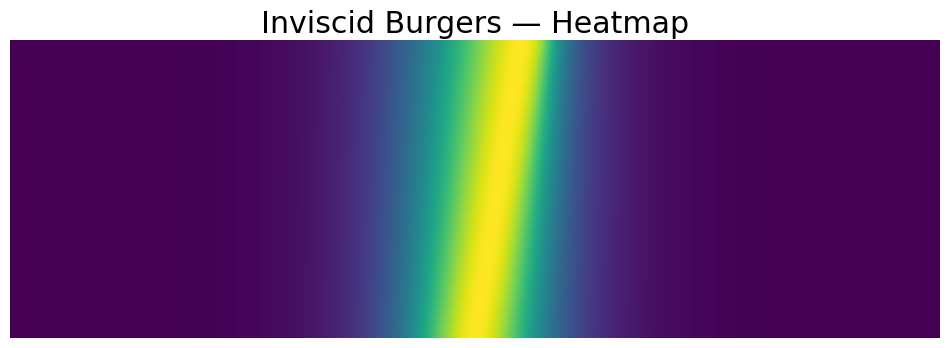

In [2]:
# Inviscid Burgers' equation (nu = 0)
nu_inviscid = 0.0

# Shorter time window -- shock forms around t ~ 1
dt_inv = 0.025
t_inv = np.arange(0, 40*dt_inv, dt_inv)  # t = 0 to 1.0

u_inv = odeint(rhsBurgers, u0, t_inv, args=(kappa, nu_inviscid))

# Waterfall plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

u_plot_inv = u_inv[0:-1:4,:]
for j in range(u_plot_inv.shape[0]):
    ys = j*np.ones(u_plot_inv.shape[1])
    ax.plot(x, ys, u_plot_inv[j,:])
ax.set_title('Inviscid Burgers — Shock Formation')

# Image plot
plt.figure()
plt.imshow(np.flipud(u_inv), aspect=8)
plt.axis('off')
plt.title('Inviscid Burgers — Heatmap')
plt.show()